In [1]:
# Load libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

In [2]:
# Load dataset
df = pd.read_csv("data.csv", sep=";")
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
df.shape

(4424, 37)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [5]:
# Check null values
df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [6]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [7]:
df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

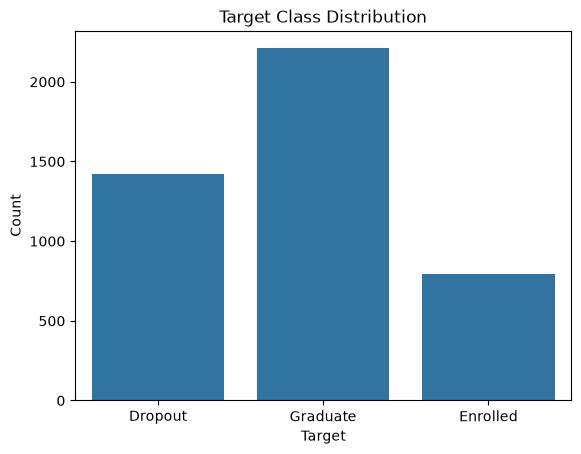

In [8]:
sns.countplot(x="Target", data=df)
plt.title("Target Class Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

In [10]:
# Convert target to numbers
df["Target"] = df["Target"].map({"Dropout": 0, "Enrolled": 1, "Graduate": 2})
df["Target"].value_counts()

Target
2    2209
0    1421
1     794
Name: count, dtype: int64

In [11]:
# Define X and y
X = df.drop(["Target"], axis=1)
y = df["Target"]

In [12]:
# Split data into train and test (5% test)
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(
    X, y, test_size=0.05, random_state=42
)
X_train_5.shape, X_test_5.shape

((4202, 36), (222, 36))

In [13]:
# Train Decision Tree and Random Forest (5% test)
dt_5 = DecisionTreeClassifier(random_state=42)
dt_5.fit(X_train_5, y_train_5)
y_pred_dt_train_5 = dt_5.predict(X_train_5)
y_pred_dt_5 = dt_5.predict(X_test_5)
dt_train_5 = metrics.accuracy_score(y_train_5, y_pred_dt_train_5)
dt_test_5 = metrics.accuracy_score(y_test_5, y_pred_dt_5)
dt_cv_5 = cross_val_score(dt_5, X_train_5, y_train_5, cv=5, scoring="accuracy").mean()
print(f"DT 5% - Train: {dt_train_5:.4f}, Test: {dt_test_5:.4f}, CV: {dt_cv_5:.4f}")

rf_5 = RandomForestClassifier(random_state=42)
rf_5.fit(X_train_5, y_train_5)
y_pred_rf_train_5 = rf_5.predict(X_train_5)
y_pred_rf_5 = rf_5.predict(X_test_5)
rf_train_5 = metrics.accuracy_score(y_train_5, y_pred_rf_train_5)
rf_test_5 = metrics.accuracy_score(y_test_5, y_pred_rf_5)
rf_cv_5 = cross_val_score(rf_5, X_train_5, y_train_5, cv=5, scoring="accuracy").mean()
print(f"RF 5% - Train: {rf_train_5:.4f}, Test: {rf_test_5:.4f}, CV: {rf_cv_5:.4f}")

DT 5% - Train: 1.0000, Test: 0.7072, CV: 0.6854
RF 5% - Train: 1.0000, Test: 0.7432, CV: 0.7787


In [14]:
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(
    X, y, test_size=0.15, random_state=42
)
X_train_15.shape, X_test_15.shape

((3760, 36), (664, 36))

In [15]:
dt_15 = DecisionTreeClassifier(random_state=42)
dt_15.fit(X_train_15, y_train_15)
y_pred_dt_train_15 = dt_15.predict(X_train_15)
y_pred_dt_15 = dt_15.predict(X_test_15)
dt_train_15 = metrics.accuracy_score(y_train_15, y_pred_dt_train_15)
dt_test_15 = metrics.accuracy_score(y_test_15, y_pred_dt_15)
dt_cv_15 = cross_val_score(
    dt_15, X_train_15, y_train_15, cv=5, scoring="accuracy"
).mean()
print(f"DT 15% - Train: {dt_train_15:.4f}, Test: {dt_test_15:.4f}, CV: {dt_cv_15:.4f}")

rf_15 = RandomForestClassifier(random_state=42)
rf_15.fit(X_train_15, y_train_15)
y_pred_rf_train_15 = rf_15.predict(X_train_15)
y_pred_rf_15 = rf_15.predict(X_test_15)
rf_train_15 = metrics.accuracy_score(y_train_15, y_pred_rf_train_15)
rf_test_15 = metrics.accuracy_score(y_test_15, y_pred_rf_15)
rf_cv_15 = cross_val_score(
    rf_15, X_train_15, y_train_15, cv=5, scoring="accuracy"
).mean()
print(f"RF 15% - Train: {rf_train_15:.4f}, Test: {rf_test_15:.4f}, CV: {rf_cv_15:.4f}")

DT 15% - Train: 1.0000, Test: 0.6732, CV: 0.6934
RF 15% - Train: 1.0000, Test: 0.7605, CV: 0.7699


In [16]:
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(
    X, y, test_size=0.25, random_state=42
)
X_train_25.shape, X_test_25.shape

((3318, 36), (1106, 36))

In [17]:
dt_25 = DecisionTreeClassifier(random_state=42)
dt_25.fit(X_train_25, y_train_25)
y_pred_dt_train_25 = dt_25.predict(X_train_25)
y_pred_dt_25 = dt_25.predict(X_test_25)
dt_train_25 = metrics.accuracy_score(y_train_25, y_pred_dt_train_25)
dt_test_25 = metrics.accuracy_score(y_test_25, y_pred_dt_25)
dt_cv_25 = cross_val_score(
    dt_25, X_train_25, y_train_25, cv=5, scoring="accuracy"
).mean()
print(f"DT 25% - Train: {dt_train_25:.4f}, Test: {dt_test_25:.4f}, CV: {dt_cv_25:.4f}")

rf_25 = RandomForestClassifier(random_state=42)
rf_25.fit(X_train_25, y_train_25)
y_pred_rf_train_25 = rf_25.predict(X_train_25)
y_pred_rf_25 = rf_25.predict(X_test_25)
rf_train_25 = metrics.accuracy_score(y_train_25, y_pred_rf_train_25)
rf_test_25 = metrics.accuracy_score(y_test_25, y_pred_rf_25)
rf_cv_25 = cross_val_score(
    rf_25, X_train_25, y_train_25, cv=5, scoring="accuracy"
).mean()
print(f"RF 25% - Train: {rf_train_25:.4f}, Test: {rf_test_25:.4f}, CV: {rf_cv_25:.4f}")

DT 25% - Train: 1.0000, Test: 0.6835, CV: 0.6899
RF 25% - Train: 1.0000, Test: 0.7767, CV: 0.7791


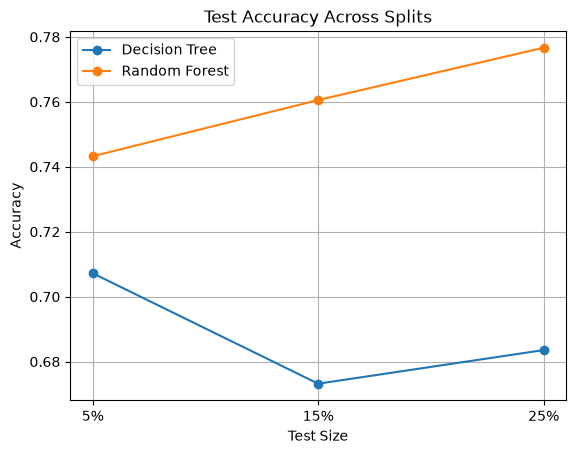

In [18]:
# Plot test accuracy for splits
splits = ["5%", "15%", "25%"]
dt_scores = [dt_test_5, dt_test_15, dt_test_25]
rf_scores = [rf_test_5, rf_test_15, rf_test_25]

plt.plot(splits, dt_scores, marker="o", label="Decision Tree")
plt.plot(splits, rf_scores, marker="o", label="Random Forest")
plt.title("Test Accuracy Across Splits")
plt.xlabel("Test Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report

In [20]:
# GridSearchCV for Decision Tree (25% test)
param_grid_dt = {
    "max_depth": [3, 5, 7, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42), param_grid_dt, cv=5, scoring="accuracy"
)
grid_dt.fit(X_train_25, y_train_25)

print("Best Parameters:", grid_dt.best_params_)
best_dt = grid_dt.best_estimator_
y_pred_dt_train_best = best_dt.predict(X_train_25)
y_pred_dt_best = best_dt.predict(X_test_25)
print(
    f"Tuned DT - Train: {metrics.accuracy_score(y_train_25, y_pred_dt_train_best):.4f}, Test: {metrics.accuracy_score(y_test_25, y_pred_dt_best):.4f}, CV: {grid_dt.best_score_:.4f}"
)

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Tuned DT - Train: 0.7764, Test: 0.7405, CV: 0.7486


In [21]:
# GridSearchCV for Random Forest (25% test)
param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, 15],
    "min_samples_leaf": [1, 2, 4],
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring="accuracy"
)
grid_rf.fit(X_train_25, y_train_25)

print("Best Parameters:", grid_rf.best_params_)
best_rf = grid_rf.best_estimator_
y_pred_rf_train_best = best_rf.predict(X_train_25)
y_pred_rf_best = best_rf.predict(X_test_25)
print(
    f"Tuned RF - Train: {metrics.accuracy_score(y_train_25, y_pred_rf_train_best):.4f}, Test: {metrics.accuracy_score(y_test_25, y_pred_rf_best):.4f}, CV: {grid_rf.best_score_:.4f}"
)

Best Parameters: {'max_depth': 15, 'min_samples_leaf': 1, 'n_estimators': 200}
Tuned RF - Train: 0.9831, Test: 0.7703, CV: 0.7770
